# 1) Géneration de variables aléatoires: méthode d'inversion

Course program (30H / 10 séances de cours de 3h)
1. generation of random variables
2. integration by montecarlo methods
3. montecarlo methods for markov chains

Controles:
- 1.30h le 14 janvier, à la fin du chapitre 2 (contenu jusqu'à vacances)
- 2/2.30h le 8 fevrier

Note finale:
0.4 C1 + 0.6 C2

Pas de documents, calculatrice type collége

## TD1, ex. 1 : variable continue

Soit $x$ une v.a. de loi de Weibull:

$$
f(x)=\theta x^{\theta -1} e^{-x^{\theta}},
$$

si $x>0$ et $f(x)=0$ sinon.


- Fonction de repartition, obtenu en integrand la loi:
$$
F(t) = P(X \leq t) = \left[ -e^{x^{\theta}} \right]_{0}^{t} = -e^{- t^{\theta}} +1 \quad \in \quad ]0,1[
$$
pour $t>0$ et $F(x)=0$ pour $t<=0$.

- F est bijective de $[0,+\infty]$ dans $]0,1[$, donc l'inverse générailsée $F^{-1}$ est égale à la fonction récriproque de $F$ restreinte sur $]0,+\infty[$.

Soit $u \in]0,1[$ et $t>0$, on obtient
$$
u = 1- e^{-t^{\theta}} \iff 1- u = e^{-t^{\theta}} \iff t^{\theta} = - ln(1-u) \iff t = \left(- ln(1-u) \right)^{\frac{1}{\theta}},
$$
d'où l'inverse généralisée est
$$
F^{-1}(u) = \left(- ln(1-u) \right)^{\frac{1}{\theta}}.
$$

- Par la méthode d'inversion, soit $U \sim \mathcal{U}(]0,1[)$, alors $F^{-1}(u) = \left(- ln(1-u) \right)^{\frac{1}{\theta}}$ est de loi de Weibull de paramétre $\theta$.

In [1]:
n <- 5000                         # nombre observations
theta <- 2                        # paramétre

set.seed(155)                     # seed
T1s <- Sys.time()                 # time

u <- runif(n)                         # U UNIFORME
vect_obs <- (-log(1-u))^(1/theta)     # LOI X \sim F^{-1}(U)

T2s <- Sys.time()
difftime(T2s,T1s)

Time difference of 0.00366497 secs

Histogramme de la loi de $X \sim F^{-1}(U)$ tracer par la méthode d'inversion:

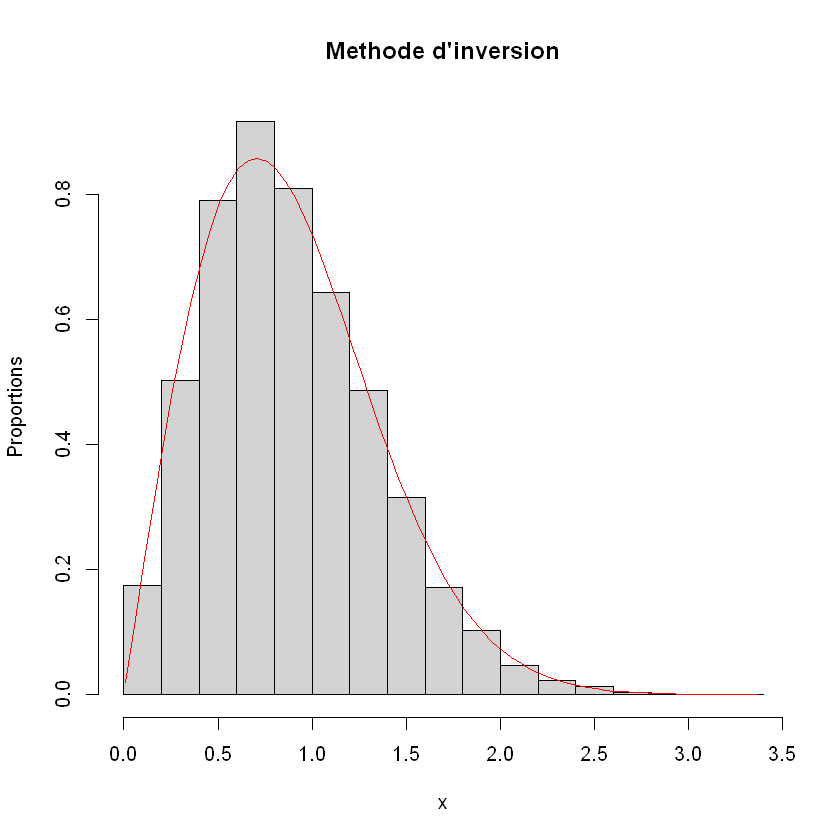

In [2]:
hist(vect_obs,freq=FALSE,  main="Methode d'inversion", xlab="x", ylab="Proportions")   # freq: pour normaliser   

xl <- seq(0.01, max(vect_obs), by=0.05)

lines(xl, theta*xl^{theta-1}*exp(-xl^{theta}), col="red")

Histogramme de la loi de $X$ exacte:

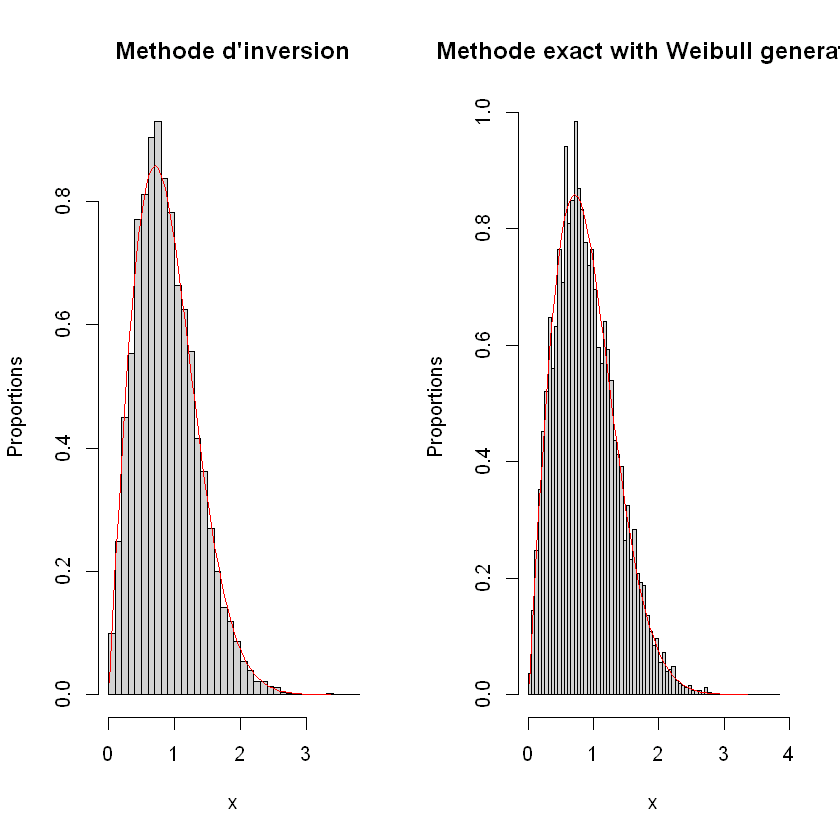

In [3]:
par(mfrow=c(1,2))
hist(vect_obs, freq=FALSE, main="Methode d'inversion", xlab="x", ylab="Proportions", breaks=seq(0, max(vect_obs)+0.5, by=0.1))
xl <- seq(0.01, max(vect_obs), by=0.05)
lines(xl, theta*xl^{theta-1}*exp(-xl^{theta}), col="red")

hist(rweibull(n, theta), freq=FALSE, main="Methode exact with Weibull generator", xlab="x", ylab="Proportions", breaks=seq(0, max(vect_obs)+0.5, by=0.05)) 
lines(xl, dweibull(xl, theta), col="red")

## TD1, ex.2 : variable discréte

Soit $X$ une v.a. de loi
$$
- P(X=1)=0.25 \quad
- P(X=2)=0.5 \quad
- P(X=3)=0.125 \quad
- P(X=4)= 0.125 \quad.
$$

Donc, la fonction de répartition est:
$$
F_{X}(t) = P(X \leq t) = \begin{cases}
0 & si \quad t<1 \\
0.25 & si \quad 1\leq t \leq 2 \\
0.75 & si \quad 2\leq t \leq 3 \\
0.875 & si \quad 3\leq t \leq 4 \\
1 & si \quad t \geq 4 \\
\end{cases}
$$

L'inverse géneralisée est
$$
F_{X}^{-1}(u) = \begin{cases}
1 & si \quad u \in]0,0.25[ \\
2 & si \quad u \in]0.25, 0.75[ \\
3 & si \quad u \in]0.75, 0.875[ \\
4 & si \quad u \in]0.875, 1[ \\
\end{cases}
$$

In [7]:
n <- 3000  # observations

u <- runif(n)      # LOI UNIFORME

x_obs <- numeric(n)

for (i in 1:n) {

  if (u[i] <= 0.25) { x_obs[i] <- 1 }
  
  else if (u[i] <= 0.75) { x_obs[i] <- 2 }
  
  else if (u[i] <= 0.875) { x_obs[i] <- 3 } 
  
  else { x_obs[i] <- 4 }
}

In [ ]:
n <- 3000

probasX <- c(0.25, 0.5, 1/8, 1/8)    # p=(p1,p2,p3,p4)
qprob0 <- c(0, cumsum(probasX))      # somme cumulative, q = c(0, 0.25, 0.75, 0.875, 1)

x_obs <- numeric(n)                  # stock observations

u <- unif(n)                         # LOI UNIFORME

for (i in 1:n) {

    x_obs[i] <- sum(qrobasX < u[i])         # rajoute à x_obs: 
}

plot(table(x_obs)/n, type="h", xlab="xi", ylab="Proportion")